<a href="https://colab.research.google.com/github/brittanybee-alt/Unsupervised-Learning/blob/main/Clustering_Case_Study_Customer_Segmentation_with_K_Means_%5BBrittany_Barrion%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
%matplotlib inline
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

# Setup Seaborn
sns.set_style("whitegrid")
sns.set_context("poster")

1. Sourcing and loading
1a. Load the data

In [21]:
df_offers = pd.read_excel("/content/WineKMC.xlsx", sheet_name=0)

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


Explore the data

In [22]:
df_offers.columns = ["offer_id", "campaign", "varietal", "min_qty", "discount", "origin", "past_peak"]
df_offers.head()

,offer_id,campaign,varietal,min_qty,discount,origin,past_peak
0,1,January,Malbec,72,56,France,False
1,2,January,Pinot Noir,72,17,France,False
2,3,February,Espumante,144,32,Oregon,True
3,4,February,Champagne,72,48,France,True
4,5,February,Cabernet Sauvignon,144,44,New Zealand,True


In [23]:
df_transactions = pd.read_excel("/content/WineKMC.xlsx", sheet_name=1)
df_transactions.columns = ["customer_name", "offer_id"]
df_transactions['n'] = 1
df_transactions.head()

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,customer_name,offer_id,n
0,Smith,2,1
1,Smith,24,1
2,Johnson,17,1
3,Johnson,24,1
4,Johnson,26,1


Cleaning, transforming and visualizing
2a. Data Wrangling

Checkup Exercise Set I

In [24]:
merged = pd.merge(df_transactions, df_offers)

pivoted = merged.pivot_table(index='customer_name', columns='offer_id', values='n', fill_value=0)

pivoted

offer_id,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,27,28,29,30,31,32
customer_name,,,,,,,,,,,,,,,,,,,,,
Adams,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
Allen,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
Anderson,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
Bailey,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
Baker,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Williams,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
Wilson,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
Wood,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


3. Modelling
3a. K-Means Clustering
3ai. Choosing K: The Elbow Sum-of-Squares Method

Checkup Exercise Set II

Text(0, 0.5, 'Sum of Squares')

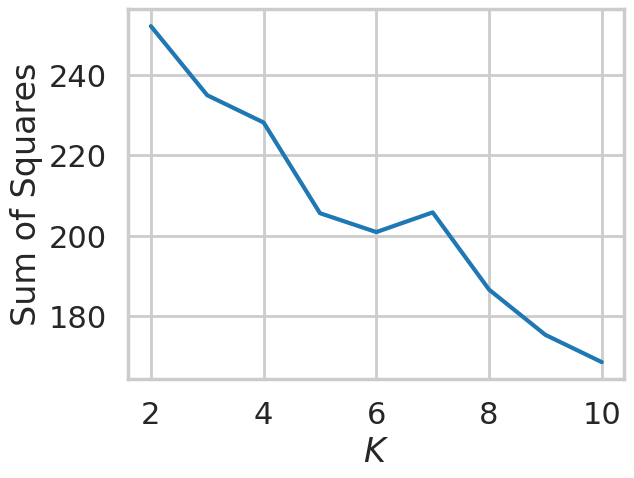

In [25]:
import sklearn.cluster
import numpy as np

ss = []

assignments = {}

X = pivoted.to_numpy()

Krange = list(range(2,11))

for K in Krange:
  model = sklearn.cluster.KMeans(n_clusters=K)
  assigned_cluster = model.fit_predict(X)
  centers = model.cluster_centers_
  ss.append(np.sum((X - centers[assigned_cluster])**2))
  assignments[str(K)] = assigned_cluster


plt.plot(Krange, ss)

plt.xlabel("$K$")
plt.ylabel("Sum of Squares")

8


([<matplotlib.axis.XTick at 0x78e945f9ee90>,
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7')])

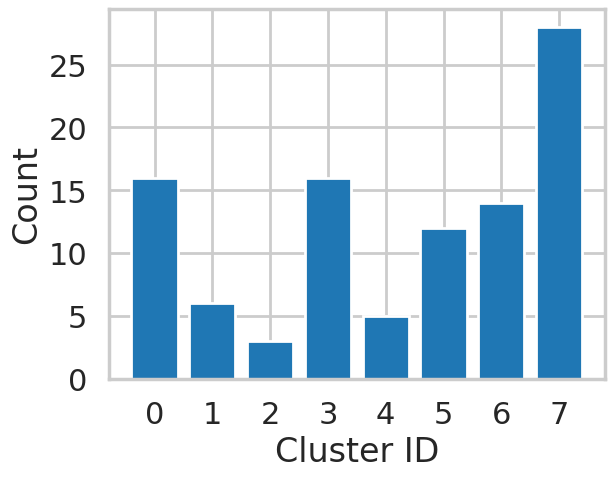

In [26]:
best_K = 8
assignments_best_K = assignments[str(best_K)]
counts = np.bincount(assignments_best_K)
print(len(counts))

plt.bar(range(best_K), counts, align='center')

plt.xlabel("Cluster ID")
plt.ylabel("Count")
plt.xticks(range(best_K))

3aii. Choosing K: The Silhouette Method

Checkup Exercise Set III

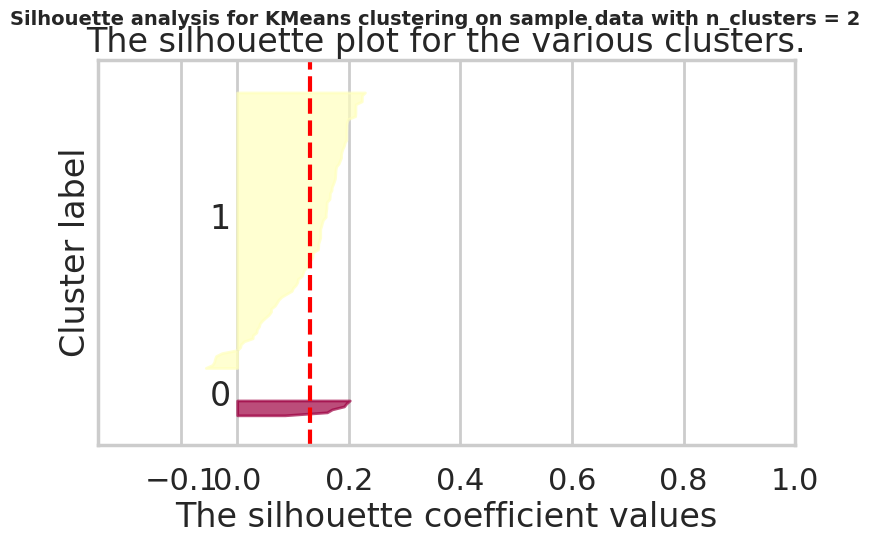

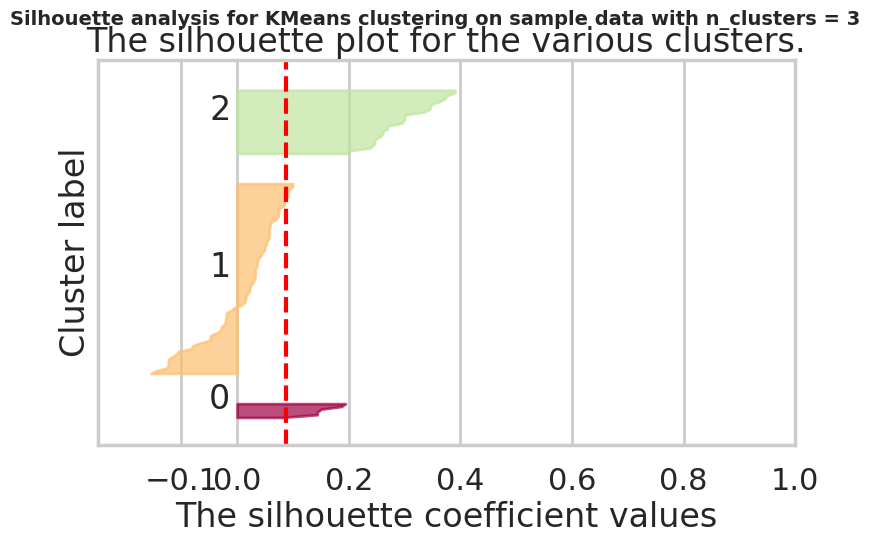

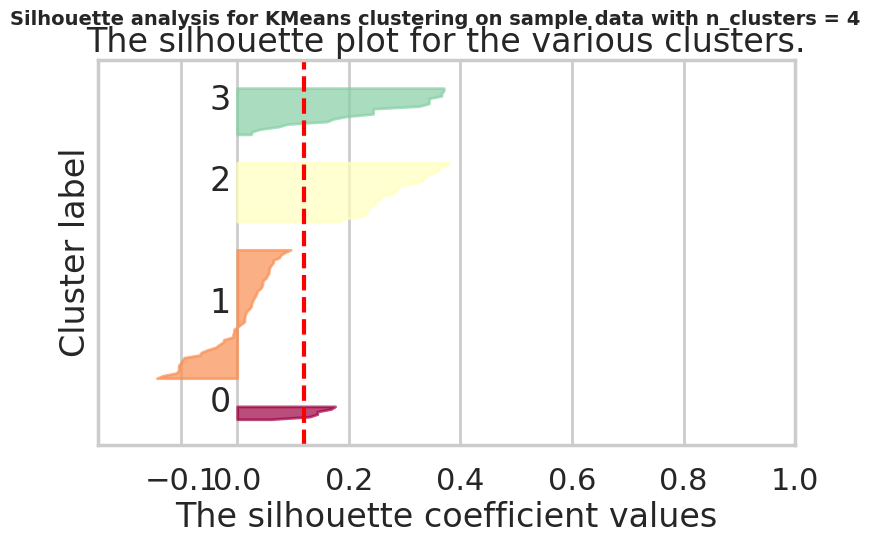

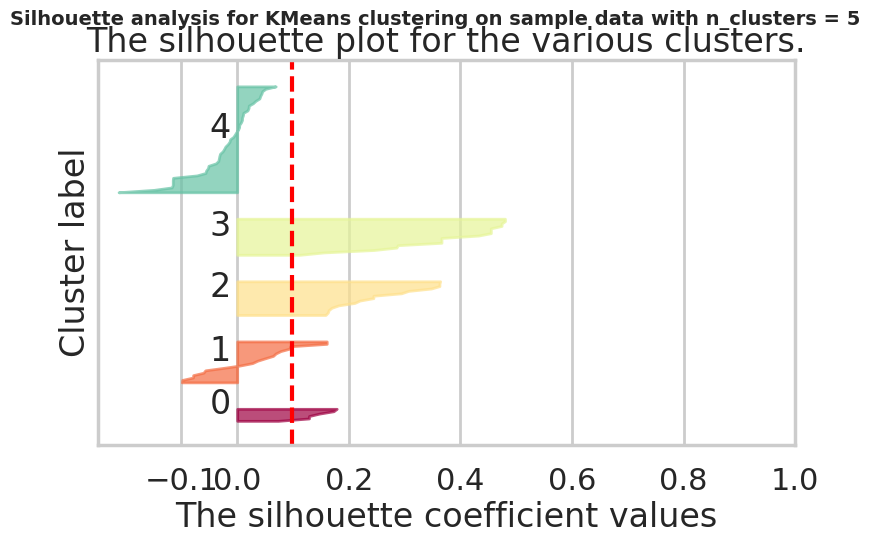

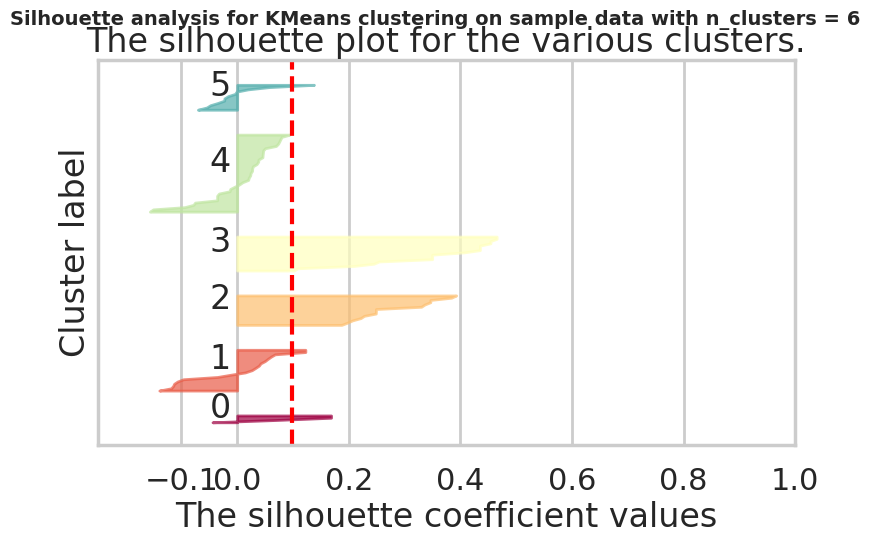

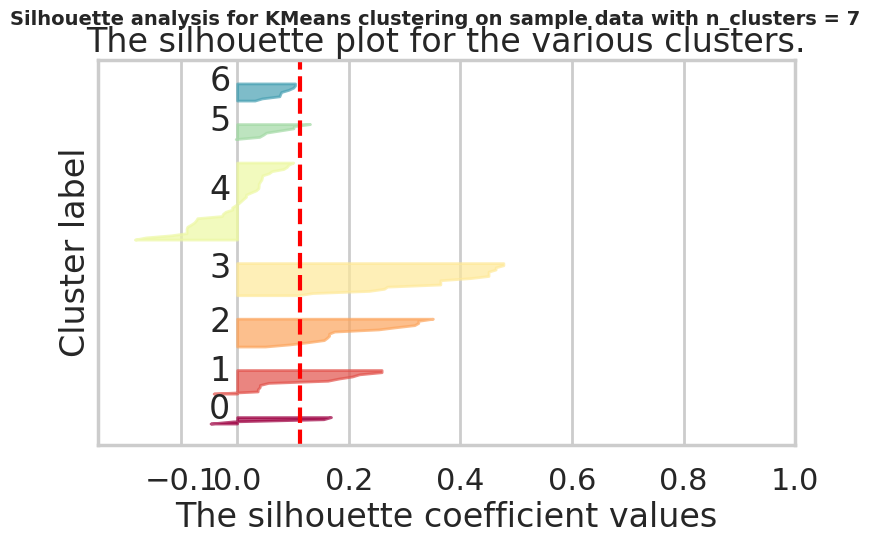

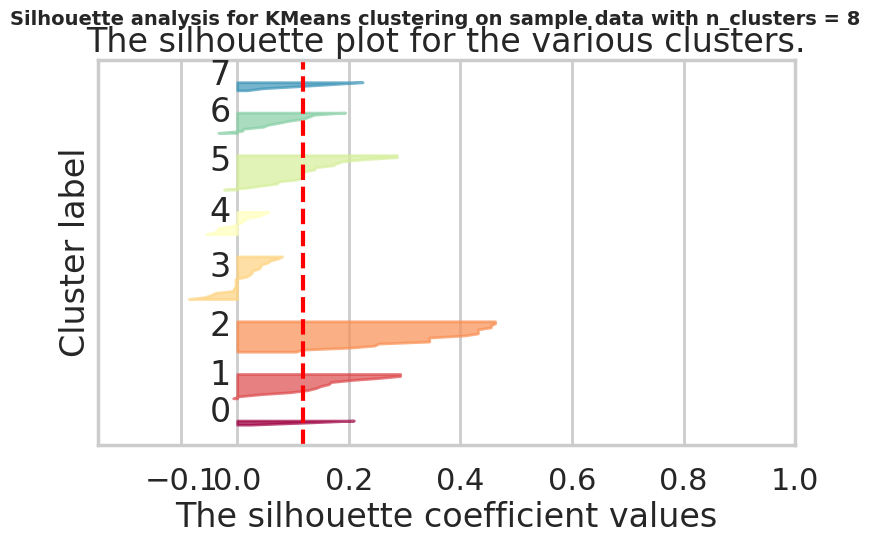

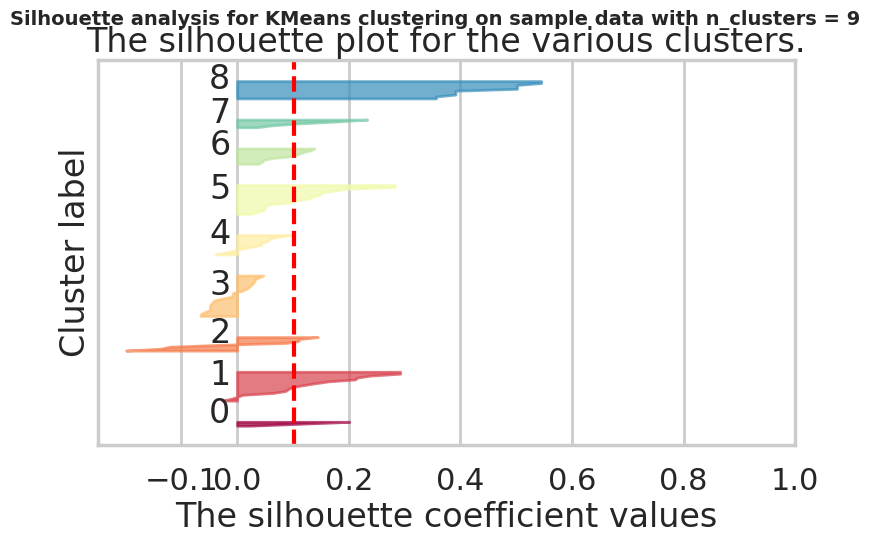

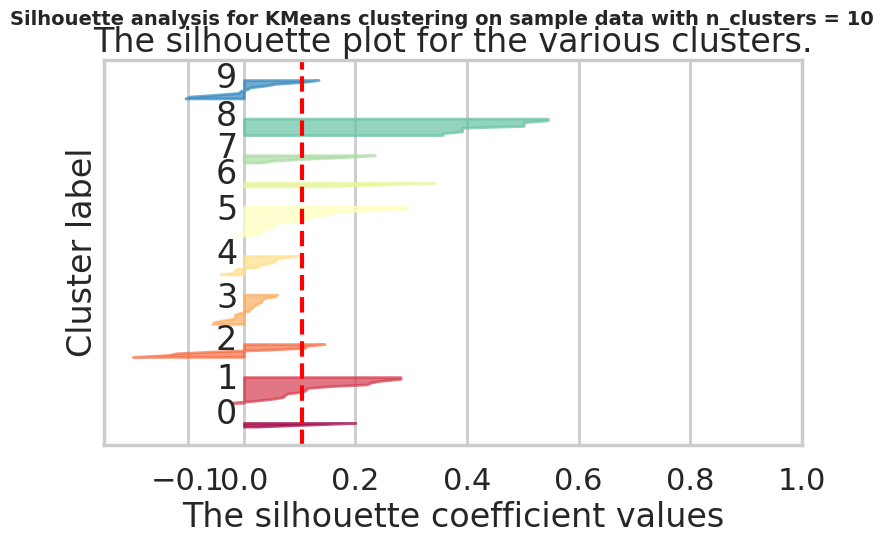

In [27]:
import sklearn.metrics
import matplotlib.cm as cm

avg_silhouette_scores = []

for K in Krange:
  fig, ax1 = plt.subplots(1, 1)
  fig.set_size_inches(9, 5)

  ax1.set_xlim([-0.25, 1])

  ax1.set_ylim([0, len(X) + (K + 1) * 10])

  clusterer = sklearn.cluster.KMeans(n_clusters=K, random_state=10)
  cluster_labels = clusterer.fit_predict(X)

  silhouette_avg = sklearn.metrics.silhouette_score(X, cluster_labels)
  avg_silhouette_scores.append(silhouette_avg)

  sample_silhouette_values = sklearn.metrics.silhouette_samples(X, cluster_labels)

  y_lower = 10
  for i in range(K):
    ith_cluster_silhouette_values = \
      sample_silhouette_values[cluster_labels == i]

    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    cmap = plt.colormaps.get_cmap("Spectral")
    color = cmap(float(i) / K)
    ax1.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)

    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

    y_lower = y_upper + 10

  ax1.set_title("The silhouette plot for the various clusters.")
  ax1.set_xlabel("The silhouette coefficient values")
  ax1.set_ylabel("Cluster label")

  ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

  ax1.set_yticks([])
  ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

  plt.suptitle(("Silhouette analysis for KMeans clustering on sample data "
                  "with n_clusters = %d" % K),
                 fontsize=14, fontweight='bold')

SOLUTIONS: Compute the average silhouette score for each  K  and plot it. What  K  does the plot suggest we should choose? Does it differ from what we found using the Elbow method?

Text(0, 0.5, 'Average Silhouette Score')

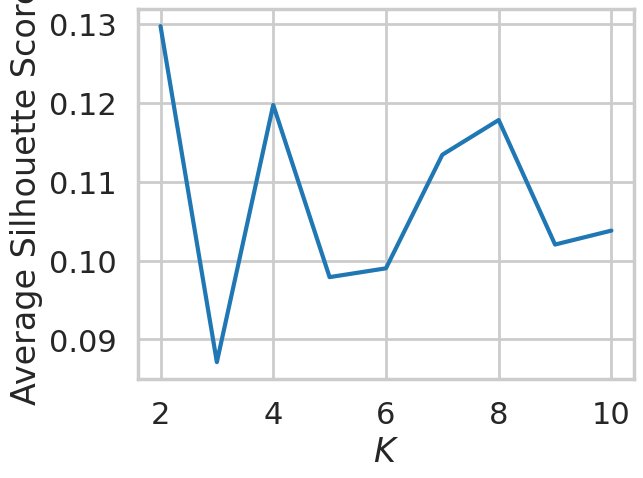

In [28]:
plt.plot(Krange, avg_silhouette_scores)

plt.xlabel("$K$")
plt.ylabel("Average Silhouette Score")

The silhouette plot peaks at K = 2, with K = 4 a close second, so it suggests choosing a small K. This differs somewhat from the elbow method, which showed a gradual decline in sum of squares with no sharp elbow, pointing to a larger K around 4 to 8. Because the silhouette scores are all low (below about 0.13), the clusters overlap and the choice of K is not clear-cut.

3aiii. Choosing K: The Gap Statistic

3b. Visualizing Clusters using PCA

Checkup Exercise Set IV

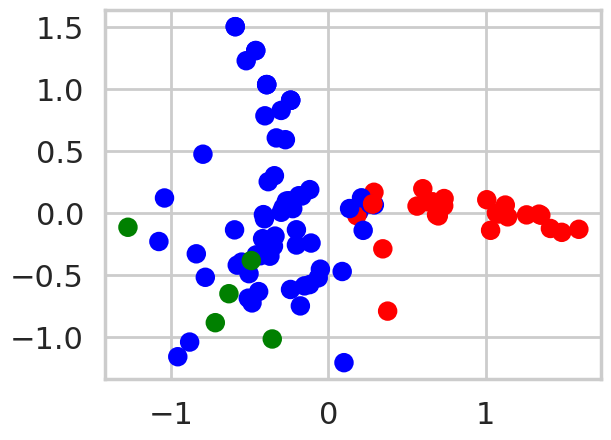

In [29]:
import sklearn.decomposition
import matplotlib.colors

model = sklearn.cluster.KMeans(n_clusters=3)

cluster_assignments = model.fit_predict(X)

cmap = matplotlib.colors.ListedColormap(['red', 'green', 'blue'])

pca = sklearn.decomposition.PCA(n_components=2)
pc1, pc2 = zip(*pca.fit_transform(X))
plt.scatter(pc1, pc2, c=cluster_assignments.tolist(), cmap=cmap)

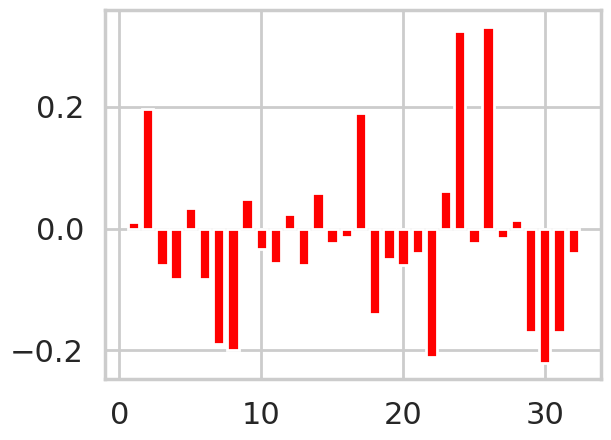

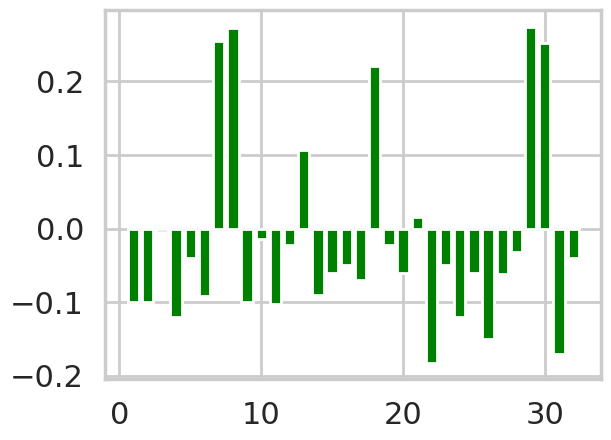

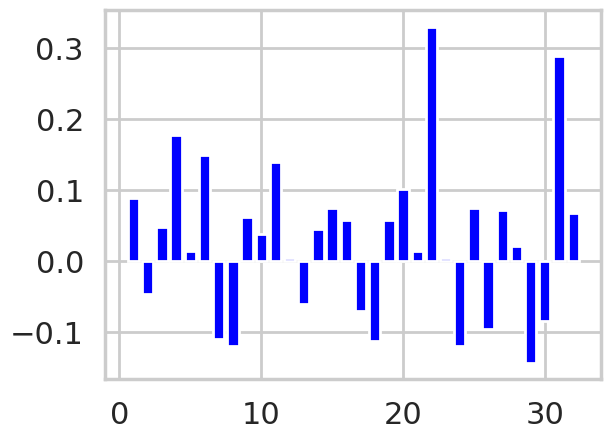

In [30]:
model = sklearn.cluster.KMeans(n_clusters=3)
cluster_assignments = model.fit_predict(X)

colors = ['red', 'green', 'blue']
offer_proportions = pivoted.sum(axis=0) / 100  # There are 100 customers
for i in range(3):
    plt.figure(i)
    cluster = pivoted[cluster_assignments == i]
    offer_proportions_cluster = cluster.sum(axis=0) / cluster.shape[0]  # Number of customers in cluster
    lift = offer_proportions_cluster - offer_proportions
    plt.bar(range(1, 33), lift, color=colors[i])

Exercise Set V

Text(0, 0.5, 'Proportion of Variance Explained')

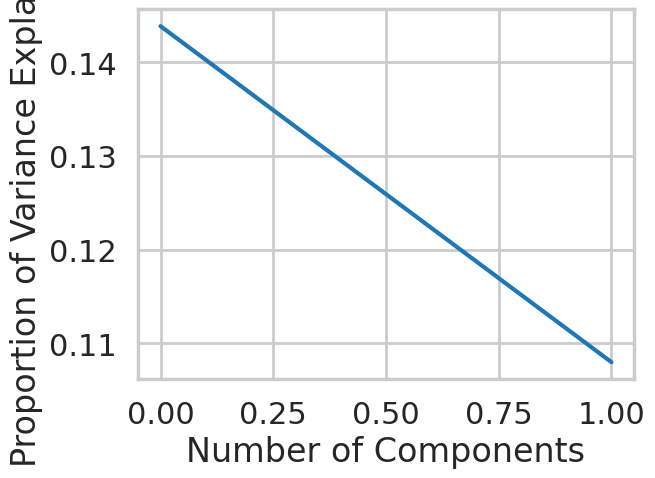

In [31]:
import sklearn.decomposition

pca = sklearn.decomposition.PCA(n_components=2)

pca.fit(X)

variance = pca.explained_variance_ratio_

plt.plot(range(len(variance)), variance)

plt.xlabel("Number of Components")
plt.ylabel("Proportion of Variance Explained")

4. Conclusions and next steps

4a. Conclusions



Conclusions

There’s no clearly best K. The elbow curve has no sharp bend, and silhouette scores peak at K = 2 but are low everywhere (under about 0.13). That means the clusters overlap.
The 2D PCA plot is limited. The first two components explain only about 25% of the variance, so the plot can’t show the full structure.
There are still some buying patterns. Some customers favor small-quantity offers (6 kg), some favor Pinot Noir, and a small group buys large-quantity sparkling wines. Most customers don’t stand out on any offer. Minimum quantity and varietal seem to matter more than discount or origin.
The takeaway: The segments are loose, so use them as a starting point for testing targeted offers, not as firm customer types.

For your mentor: The dataset is small (100 customers), and K-means results shift with the random seed. Would a different method or distance measure, like cosine similarity, separate customers better?

4b. Other clustering algorithms

Exercise Set IV

In [32]:
import sklearn.cluster
import sklearn.metrics

# 1. Affinity propagation (chooses the number of clusters itself)
affinity = sklearn.cluster.AffinityPropagation(random_state=10)
labels_affinity = affinity.fit_predict(X)

# 2. Spectral clustering (you choose K)
spectral = sklearn.cluster.SpectralClustering(n_clusters=4, random_state=10)
labels_spectral = spectral.fit_predict(X)

# 3. Agglomerative clustering (you choose K)
agglom = sklearn.cluster.AgglomerativeClustering(n_clusters=4)
labels_agglom = agglom.fit_predict(X)

# 4. DBSCAN (finds clusters by density; label -1 means "noise")
dbscan = sklearn.cluster.DBSCAN(eps=1.5, min_samples=3)
labels_dbscan = dbscan.fit_predict(X)

# Compare the first three with silhouette scores
for name, labels in [("Affinity", labels_affinity),
                     ("Spectral", labels_spectral),
                     ("Agglomerative", labels_agglom)]:
    print(name, "clusters:", len(set(labels)), "silhouette:", sklearn.metrics.silhouette_score(X, labels))

Affinity clusters: 14 silhouette: 0.12227751845150901
Spectral clusters: 4 silhouette: 0.08627893400734331
Agglomerative clusters: 4 silhouette: 0.128937578158815


Agglomerative clustering gave results closest to K-means, with the highest silhouette score. Affinity propagation found many small clusters, spectral clustering scored lowest, and DBSCAN couldn’t separate the data into meaningful groups. None of the methods produced strongly separated clusters, which fits the low silhouette scores and the overlap we saw earlier.